# More models: weather, calendar, and recent generation

Run `python session1_more_models.py` to reproduce the experiment. This notebook displays its saved results.

We add seasonal averages, Ridge regression, histogram gradient boosting, Extra Trees, and Random Forest. Features include hourly Fourier terms, weekend, and generation lags of 48, 72, and 168 hours. Weather models add the supplied weather, wind powers, and clear-day/hour interactions. All target lags are known at the start of a 48-hour forecast; no actual target from the forecast window enters prediction.

Trees can capture nonlinear effects such as wind speed and cloud cover. Ridge is a regularized linear comparison. Recent training windows adapt to the changing generation scale. These feature choices are hypotheses, not proof of the portfolio's physical composition.

## Fair comparisons and limitations
We reuse the previous six calibration, five selection, and one audit blocks, each 48 hours. Fits and interval calibration use only earlier information. SARIMA and seasonal naive are rerun alongside the new models.

**Observed-weather results are optimistic:** the training file contains actual weather, while the real future inputs are weather forecasts. We also test three reproducible perturbed-weather scenarios per block. The model is selected by lowest pooled RMSE under this stress scenario, with baseline eligible.

**Stress is illustrative, not a measured weather-error model.** Day-one perturbation scales are 2°C temperature, 1 m/s wind, 0.25 cloud cover, 2 mmHg pressure, and 5 humidity percentage points. Day two uses 1.5 times those scales. Errors combine a shared daily component with hourly noise. Daylight is unchanged and density adjusts with temperature/pressure. These assumptions could overstate or understate the actual forecast error. Three scenarios do not provide three independent historical windows.

Selection windows have now been reused across model searches, so winning scores can be optimistic. The final historical window was previously seen and is an audit, not an untouched test set. Hidden forecast accuracy remains unknown.

Non-baseline intervals use the 95th percentile of absolute errors from the six earlier calibration blocks, separately by forecast day and weather scenario. The actual submission uses all available stress-scenario errors after selecting a model. These are nominal 95% intervals without a coverage guarantee.


In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd()/'scripts'))

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
out=Path("results/more")
summary=pd.read_csv(out/"model_comparison.csv")
pred=pd.read_csv(out/"validation_predictions.csv",parse_dates=["ds"])
report=json.loads((out/"run_summary.json").read_text())
winner=report["selected_model"]
print("Selected model:",winner)
for scenario in ["observed_weather","weather_stress"]:
    print("\n",scenario)
    display(summary[(summary.phase=="selection")&(summary.scenario==scenario)].set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))


Selected model: weather_ridge_21d

 observed_weather


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
weather_ridge_21d,262.947,0.840,927.169,1060.516,0.996
weather_boosting_60d,265.651,0.849,804.347,1193.376,0.912
weather_extra_trees_60d,269.525,0.861,611.734,1284.776,0.925
weather_ridge_60d,270.917,0.866,1177.143,1060.300,0.933
weather_boosting_120d,271.955,0.869,981.288,1112.154,0.912
SARIMA_101_110_24_21d,295.532,0.944,490.494,1173.162,0.975
weather_random_forest_60d,310.039,0.991,1096.994,1203.384,0.962
seasonal_naive,312.953,1.000,765.279,2206.476,0.796
seasonal_mean_3d,357.659,1.143,1258.648,1301.873,0.967



 weather_stress


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
weather_ridge_21d,276.457,0.883,906.875,1140.934,0.997
weather_boosting_60d,278.723,0.891,867.971,1116.181,0.954
weather_extra_trees_60d,283.573,0.906,707.942,1116.487,0.956
weather_ridge_60d,285.001,0.911,1108.105,1090.193,0.965
weather_boosting_120d,291.213,0.931,1027.958,1157.609,0.946
SARIMA_101_110_24_21d,295.532,0.944,490.494,1173.162,0.975
seasonal_naive,312.953,1.000,765.279,2206.476,0.796
weather_random_forest_60d,322.329,1.030,1247.084,1224.694,0.965
seasonal_mean_3d,357.659,1.143,1258.648,1301.873,0.967


## Weather sensitivity
Compare the same model with observed versus perturbed weather. A ratio below 1 beats seasonal naive on these hours.

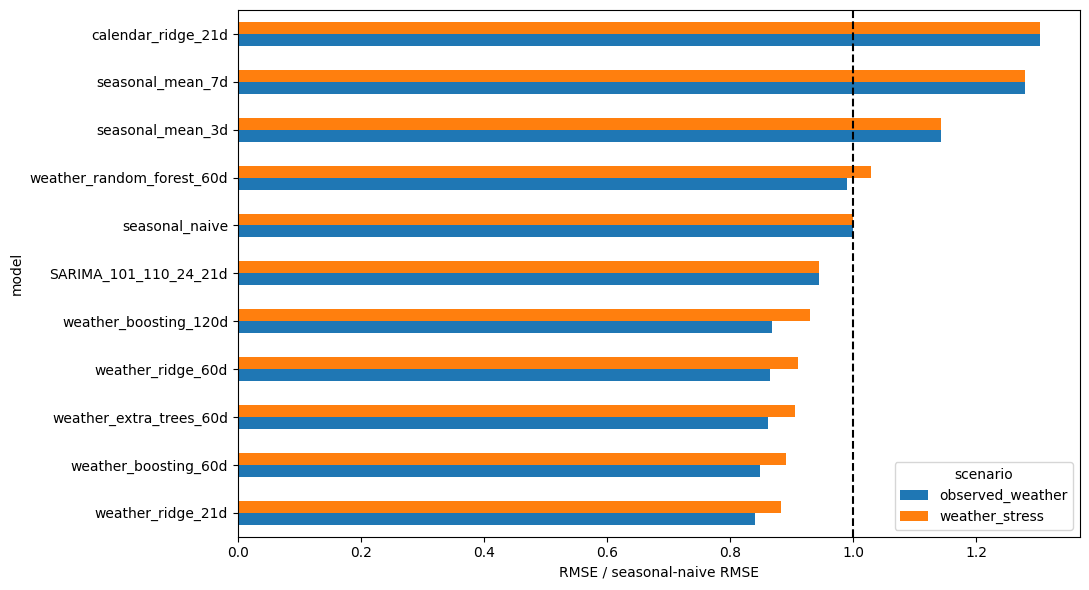

In [2]:
g=summary[summary.phase=="selection"]
pivot=g.pivot(index="model",columns="scenario",values="RMSE_ratio").sort_values("weather_stress")
ax=pivot.plot.barh(figsize=(11,6))
ax.axvline(1,color="black",linestyle="--"); ax.set_xlabel("RMSE / seasonal-naive RMSE")
plt.tight_layout(); plt.show()


## Comparison across individual 48-hour windows
Choose `SCENARIO` below: `weather_stress` or `observed_weather`. Tables include dated selection windows and the previously seen audit window, clearly labeled. **RMSE ratio below 1 means better than baseline.**

Stress-scenario errors are pooled within each real historical window; the three seeds are not counted as three independent windows. Win counts and consistency statistics use only the five selection windows. Mean window RMSE is descriptive and differs from the pooled RMSE used to select the model. The audit does not affect selection or win counts.

CSV exports: `window_comparison.csv` contains all metrics by window; `window_consistency.csv` contains win counts and best/worst relative performance. Wide RMSE and ratio tables are also saved for each scenario.


In [3]:
SCENARIO = "weather_stress"  # alternatively: "observed_weather"
window_scores = pd.read_csv(out / "window_comparison.csv", parse_dates=["start", "end"])
consistency = pd.read_csv(out / "window_consistency.csv")
w = window_scores[window_scores.scenario == SCENARIO].copy()
w["window"] = w.start.dt.strftime("%b %d %H:%M") + " → " + w.end.dt.strftime("%b %d %H:%M") + np.where(w.phase.eq("selection"), " [selection]", " [audit]")
order = summary[(summary.phase == "selection") & (summary.scenario == SCENARIO)].sort_values("RMSE").model.tolist()
window_order = w.sort_values("start").window.drop_duplicates().tolist()
rmse_table = w.pivot(index="model", columns="window", values="RMSE").reindex(index=order, columns=window_order)
ratio_table = w.pivot(index="model", columns="window", values="RMSE_ratio").reindex(index=order, columns=window_order)
print("RMSE in generation units — lower is better")
display(rmse_table.round(2))
print("RMSE / baseline RMSE — below 1 wins")
display(ratio_table.round(3))
print("Consistency across the five selection windows only")
display(consistency[consistency.scenario == SCENARIO].set_index("model").drop(columns="scenario").round(3))


RMSE in generation units — lower is better


window,Oct 15 01:00 → Oct 17 00:00 [selection],Oct 17 01:00 → Oct 19 00:00 [selection],Oct 19 01:00 → Oct 21 00:00 [selection],Oct 21 01:00 → Oct 23 00:00 [selection],Oct 23 01:00 → Oct 25 00:00 [selection],Oct 25 01:00 → Oct 27 00:00 [audit]
model,,,,,,
weather_ridge_21d,322.59,355.07,247.02,173.87,246.48,215.63
weather_boosting_60d,327.53,325.95,224.39,271.96,224.95,264.10
weather_extra_trees_60d,301.03,301.07,213.53,262.85,325.76,235.82
weather_ridge_60d,347.30,373.15,262.10,182.75,210.19,226.99
weather_boosting_120d,326.57,338.70,253.17,275.96,249.82,250.48
SARIMA_101_110_24_21d,364.89,364.64,278.01,249.77,175.84,116.11
seasonal_naive,389.32,429.70,282.72,202.00,180.97,120.40
weather_random_forest_60d,360.66,363.27,278.65,241.91,348.24,238.52
seasonal_mean_3d,304.67,364.19,493.61,349.08,220.53,131.27


RMSE / baseline RMSE — below 1 wins


window,Oct 15 01:00 → Oct 17 00:00 [selection],Oct 17 01:00 → Oct 19 00:00 [selection],Oct 19 01:00 → Oct 21 00:00 [selection],Oct 21 01:00 → Oct 23 00:00 [selection],Oct 23 01:00 → Oct 25 00:00 [selection],Oct 25 01:00 → Oct 27 00:00 [audit]
model,,,,,,
weather_ridge_21d,0.829,0.826,0.874,0.861,1.362,1.791
weather_boosting_60d,0.841,0.759,0.794,1.346,1.243,2.193
weather_extra_trees_60d,0.773,0.701,0.755,1.301,1.800,1.959
weather_ridge_60d,0.892,0.868,0.927,0.905,1.161,1.885
weather_boosting_120d,0.839,0.788,0.895,1.366,1.380,2.080
SARIMA_101_110_24_21d,0.937,0.849,0.983,1.236,0.972,0.964
seasonal_naive,1.000,1.000,1.000,1.000,1.000,1.000
weather_random_forest_60d,0.926,0.845,0.986,1.198,1.924,1.981
seasonal_mean_3d,0.783,0.848,1.746,1.728,1.219,1.090


Consistency across the five selection windows only


,windows,wins,mean_RMSE,median_RMSE_ratio,best_RMSE_ratio,worst_RMSE_ratio,mean_rank,win_rate
model,,,,,,,,
weather_ridge_21d,5,4,269.005,0.861,0.826,1.362,3.8,0.8
weather_ridge_60d,5,4,275.096,0.905,0.868,1.161,5.2,0.8
SARIMA_101_110_24_21d,5,4,286.629,0.972,0.849,1.236,6.0,0.8
weather_extra_trees_60d,5,3,280.849,0.773,0.701,1.800,3.4,0.6
weather_boosting_60d,5,3,274.955,0.841,0.759,1.346,4.6,0.6
weather_boosting_120d,5,3,288.844,0.895,0.788,1.380,5.6,0.6
weather_random_forest_60d,5,3,318.547,0.986,0.845,1.924,7.0,0.6
seasonal_mean_3d,5,2,346.416,1.219,0.783,1.746,6.8,0.4
seasonal_mean_7d,5,2,391.827,1.307,0.718,2.836,7.0,0.4


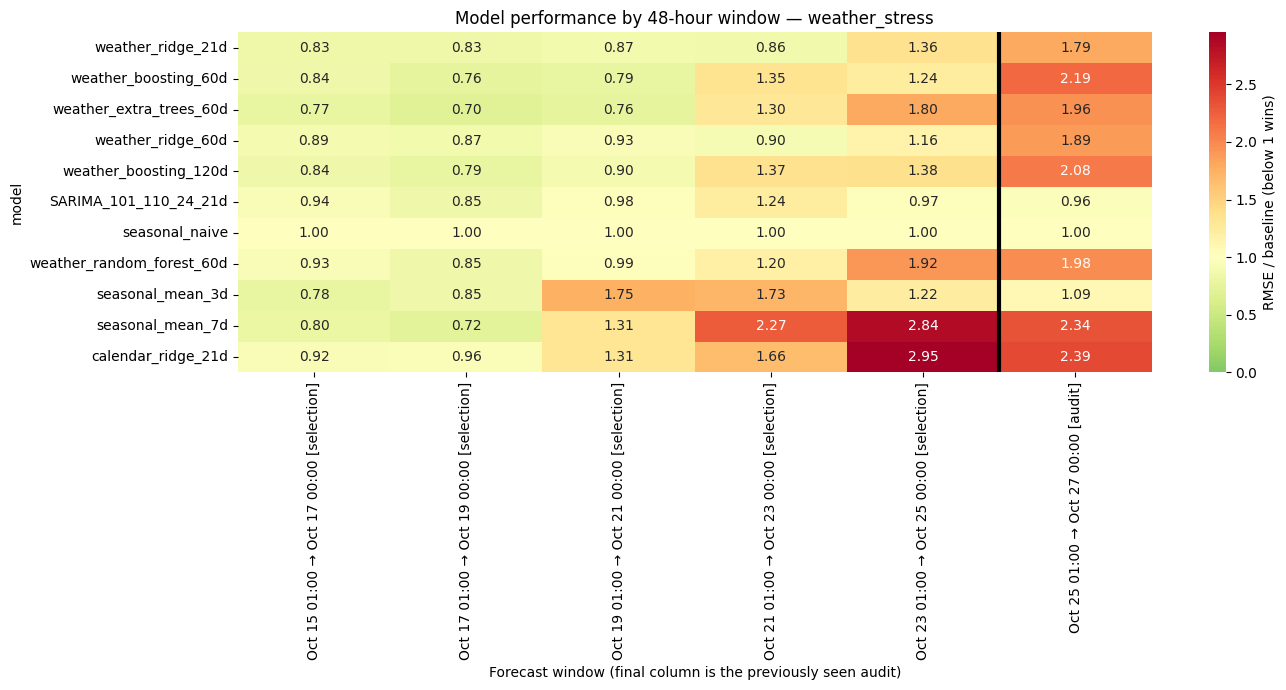

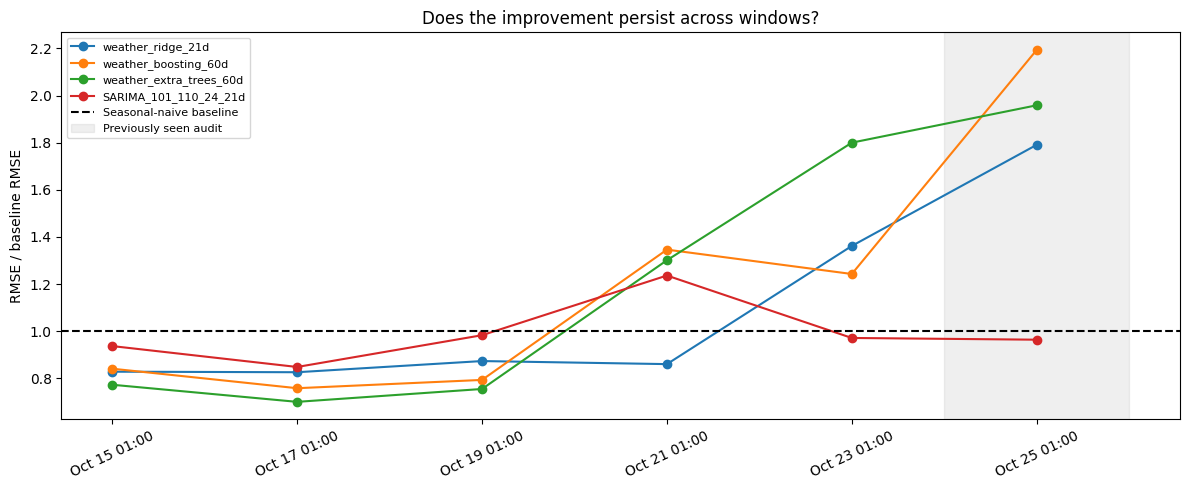

In [4]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(ratio_table, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1, vmin=0, vmax=max(2, ratio_table.to_numpy().max()), ax=ax,
            cbar_kws={"label": "RMSE / baseline (below 1 wins)"})
ax.axvline(5, color="black", linewidth=3)
ax.set_title(f"Model performance by 48-hour window — {SCENARIO}")
ax.set_xlabel("Forecast window (final column is the previously seen audit)")
plt.tight_layout()
fig.savefig(out / f"window_heatmap_{SCENARIO}.png", dpi=160, bbox_inches="tight")
plt.show()
# Keep the line chart readable while the heatmap covers every candidate.
focus = list(dict.fromkeys([winner, "weather_boosting_60d", "weather_extra_trees_60d", "SARIMA_101_110_24_21d"]))
fig, ax = plt.subplots(figsize=(12, 5))
for model in focus:
    ax.plot(range(len(window_order)), ratio_table.loc[model], marker="o", label=model)
ax.axhline(1, color="black", linestyle="--", label="Seasonal-naive baseline")
ax.axvspan(4.5, 5.5, color="gray", alpha=.12, label="Previously seen audit")
ax.set_xticks(range(len(window_order)))
ax.set_xticklabels([label.split(" → ")[0] for label in window_order], rotation=25)
ax.set_ylabel("RMSE / baseline RMSE"); ax.set_title("Does the improvement persist across windows?")
ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(out / f"window_lines_{SCENARIO}.png", dpi=160, bbox_inches="tight")
plt.show()


## Previously seen last-window audit

,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
SARIMA_101_110_24_21d,116.108,0.964,38.789,1017.788,1.000
seasonal_naive,120.404,1.000,51.088,568.464,1.000
seasonal_mean_3d,131.269,1.090,37.313,1075.895,1.000
weather_ridge_21d,215.634,1.791,85.048,1059.085,1.000
weather_ridge_60d,226.988,1.885,93.375,930.526,0.993
weather_extra_trees_60d,235.823,1.959,140.748,982.139,1.000
weather_random_forest_60d,238.515,1.981,176.088,1112.577,1.000
weather_boosting_120d,250.481,2.080,147.637,996.306,0.958
weather_boosting_60d,264.097,2.193,133.085,1026.947,0.965


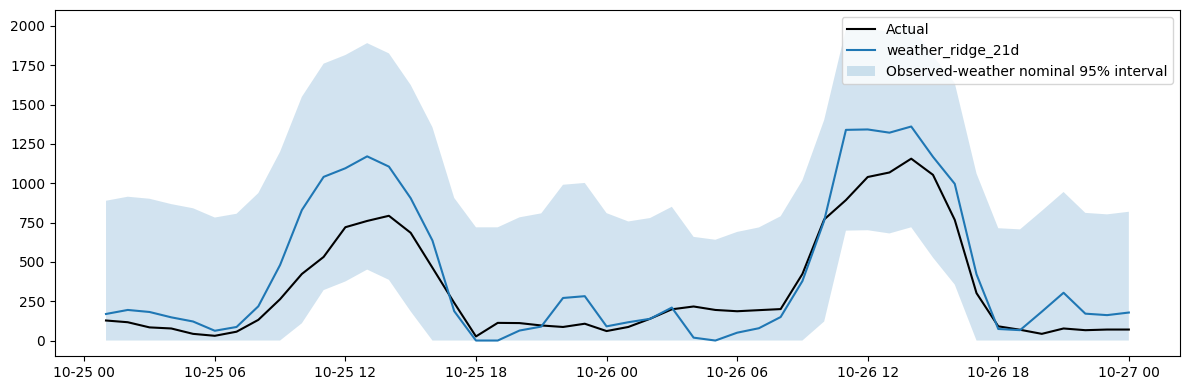

In [5]:
display(summary[(summary.phase=="last_window_audit")&(summary.scenario=="weather_stress")].set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))
g=pred[(pred.model==winner)&(pred.phase=="last_window_audit")&(pred.scenario=="observed_weather")]
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(g.ds,g.actual,label="Actual",color="black")
ax.plot(g.ds,g.forecast,label=winner)
ax.fill_between(g.ds,g.lower_95,g.upper_95,alpha=.2,label="Observed-weather nominal 95% interval")
ax.legend();plt.tight_layout();plt.show()


## New 48-hour forecast
This forecast uses the provided future weather without adding random noise to its point estimate. Its intervals use stress-scenario historical errors. The earlier SARIMA forecast remains in `results/`; the new candidate is in `results/more/`.

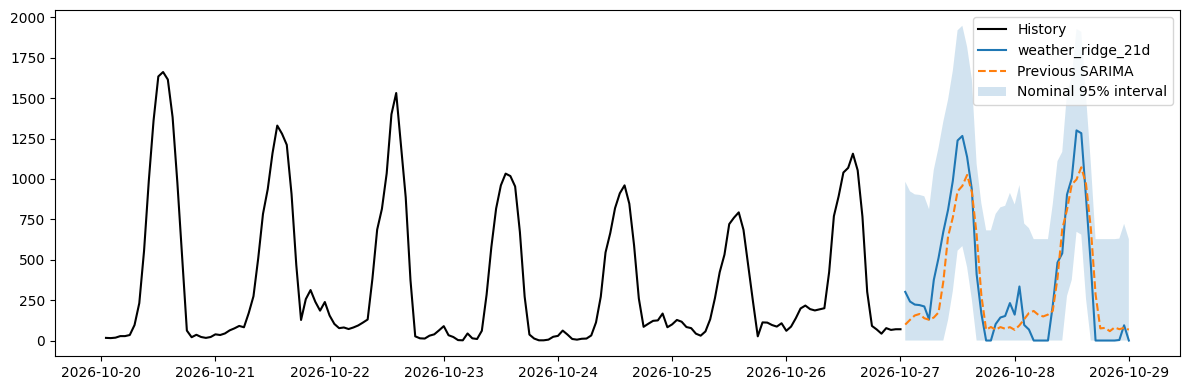

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,301.076713,0.0,983.009332
1,2026-10-27 02:00:00,241.365206,0.0,923.297826
2,2026-10-27 03:00:00,222.615433,0.0,904.548053
3,2026-10-27 04:00:00,219.377830,0.0,901.310449
4,2026-10-27 05:00:00,210.929392,0.0,892.862012


In [6]:
data=pd.read_csv("train.csv",parse_dates=["ds"])
submission=pd.read_csv(out/"selected_model_forecast.csv",parse_dates=["ds"])
old=pd.read_csv("results/ets_arima/selected_model_forecast.csv",parse_dates=["ds"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:],data.y.iloc[-168:],label="History",color="black")
ax.plot(submission.ds,submission.forecast,label=winner)
ax.plot(old.ds,old.forecast,label="Previous SARIMA",linestyle="--")
ax.fill_between(submission.ds,submission.lower_95,submission.upper_95,alpha=.2,label="Nominal 95% interval")
ax.legend();plt.tight_layout();plt.show()
display(submission.head())


## Save for Moodle
Enter your surname to save the new candidate with the required filename. This does not upload it.

In [7]:
SURNAME=""
if SURNAME.strip():
    assert not any(x in SURNAME for x in "/\\")
    filename=f"{SURNAME.strip().upper()}_project.csv"
    pd.read_csv(out/"selected_model_forecast.csv").to_csv(filename,index=False)
    print("Saved",filename)
else:
    print("Set SURNAME to write the Moodle filename.")


Set SURNAME to write the Moodle filename.
